# 03_Duong – Database 2 (SQLite) + Data Cleaning

**Thành viên:** Dương  
**Nối tiếp:** Yến – Prepare Data + Data Integration → Linh – Qdrant → Dương – SQLite + Cleaning

## Luồng dữ liệu

`merged_data.csv` → **SQLite** → đọc dữ liệu từ SQLite → **Missing Assessment** → **Imputation** → **Validation** → `cleaned_data.csv`

> `cleaned_data.csv` là đầu ra sạch để Hải và Tài tiếp tục thực hiện Univariate EDA và Multivariate EDA.


## 1. Import thư viện

In [2]:
import pandas as pd
import numpy as np
import sqlite3
import os
import matplotlib.pyplot as plt


## 2. Đọc dữ liệu đầu vào từ Yến/Linh

Nguồn đầu vào chính của phần này là `merged_data.csv` – dữ liệu đã được Yến tích hợp từ Unified Static Master và Dynamic Data.


In [ ]:
INPUT_FILE = "merged_data.csv"

df = pd.read_csv(INPUT_FILE)

print("Kích thước dữ liệu:", df.shape)
print("Số dòng:", len(df))
print("Số cột:", len(df.columns))

display(df.head())

## 3. Kiểm tra dữ liệu trước khi đưa vào SQLite

In [ ]:
print("Tên các cột:")
print(df.columns.tolist())

print("\nKiểu dữ liệu:")
display(df.dtypes.to_frame("dtype"))

print("\nSố dòng trùng:", df.duplicated().sum())

print("\nGiá trị thiếu:")
missing_before = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percent": (df.isna().mean() * 100).round(2)
}).sort_values("Missing_Count", ascending=False)

display(missing_before)


Tên các cột:
['product_name', 'price', 'tv_type', 'screen_size', 'resolution', 'screen_type', 'operating_system', 'ram', 'rom', 'release_year', 'manufacturer', 'model_name', 'rating', 'num_reviews', 'specifications', 'source', 'monthly_views', 'monthly_orders', 'customer_rating', 'stock_quantity', 'data_date']

Kiểu dữ liệu:


,dtype
product_name,str
price,float64
tv_type,str
screen_size,str
resolution,str
screen_type,str
operating_system,str
ram,str
rom,str
release_year,str



Số dòng trùng: 0

Giá trị thiếu:


,Missing_Count,Missing_Percent
num_reviews,653,94.78
rating,578,83.89
model_name,538,78.08
rom,395,57.33
ram,395,57.33
tv_type,387,56.17
screen_type,387,56.17
release_year,387,56.17
resolution,387,56.17
operating_system,387,56.17


## 4. Database 2 – SQLite

Sử dụng SQLite làm cơ sở dữ liệu quan hệ thứ hai của nhóm.

- Database: `tv_products.db`
- Table: `merged_data`
- Dữ liệu được nạp trực tiếp từ `merged_data.csv`.


In [ ]:
DB_FILE = "tv_products.db"
TABLE_NAME = "merged_data"

conn = sqlite3.connect(DB_FILE)

# Ghi dữ liệu vào SQLite
df.to_sql(
    TABLE_NAME,
    conn,
    if_exists="replace",
    index=False
)

print("Đã tạo/nạp bảng SQLite:", TABLE_NAME)


Đã tạo/nạp bảng SQLite: merged_data


## 5. Kiểm tra dữ liệu trong SQLite

In [ ]:
# Danh sách bảng
tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table';",
    conn
)

display(tables)

# Đếm số records
record_count = pd.read_sql_query(
    f"SELECT COUNT(*) AS total_records FROM {TABLE_NAME};",
    conn
)

display(record_count)

# Xem 5 records đầu
sample_sql = pd.read_sql_query(
    f"SELECT * FROM {TABLE_NAME} LIMIT 5;",
    conn
)

display(sample_sql)


,name
0,merged_data


,total_records
0,689


,product_name,price,tv_type,screen_size,resolution,screen_type,operating_system,ram,rom,release_year,...,model_name,rating,num_reviews,specifications,source,monthly_views,monthly_orders,customer_rating,stock_quantity,data_date
0,Smart Tivi QNED LG AI 4K 65 inch 65QNED70BSA,18390000.0,Smart Tivi QNED,65 inch,4K (Ultra HD),Đèn nền: <a href='https://www.dienmayxanh.com/...,webOS 26,Hãng không công bố,Hãng không công bố,2026,...,None,None,None,None,dienmayxanh,7370,453,3.2,145,2026-01-01
1,Google Tivi Sony 4K 65 inch K-65S25VM2,19990000.0,Google Tivi,65 inch,4K (Ultra HD),Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,Hãng không công bố,16 GB,2025,...,None,None,None,None,dienmayxanh,960,373,4.3,66,2026-01-02
2,Google Tivi QLED TCL AI FHD 40 inch 40S5K,7690000.0,Google Tivi QLED,40 inch,Full HD,Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,1 GB,8 GB,2025,...,None,None,None,None,dienmayxanh,5490,492,4.5,41,2026-01-03
3,Google Tivi Sony 32 inch KD-32W830K,7690000.0,Google Tivi,32 inch,HD,Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,Hãng không công bố,16 GB,2022,...,None,None,None,None,dienmayxanh,5291,292,4.7,117,2026-01-04
4,Google Tivi QLED TCL 4K 65 inch 65P7L,18490000.0,Google Tivi QLED,65 inch,4K (Ultra HD),Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,2 GB,16 GB,2026,...,None,None,None,None,dienmayxanh,5834,38,3.2,124,2026-01-05


## 6. Đọc dữ liệu trở lại từ SQLite

Bước này chứng minh dữ liệu sau khi lưu vào SQLite có thể được kết nối và đọc lại bằng Python.


In [ ]:
df_sql = pd.read_sql_query(
    f"SELECT * FROM {TABLE_NAME}",
    conn
)

print("Kích thước đọc từ SQLite:", df_sql.shape)
display(df_sql.head())


Kích thước đọc từ SQLite: (689, 21)


,product_name,price,tv_type,screen_size,resolution,screen_type,operating_system,ram,rom,release_year,...,model_name,rating,num_reviews,specifications,source,monthly_views,monthly_orders,customer_rating,stock_quantity,data_date
0,Smart Tivi QNED LG AI 4K 65 inch 65QNED70BSA,18390000.0,Smart Tivi QNED,65 inch,4K (Ultra HD),Đèn nền: <a href='https://www.dienmayxanh.com/...,webOS 26,Hãng không công bố,Hãng không công bố,2026,...,NaN,NaN,NaN,NaN,dienmayxanh,7370,453,3.2,145,2026-01-01
1,Google Tivi Sony 4K 65 inch K-65S25VM2,19990000.0,Google Tivi,65 inch,4K (Ultra HD),Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,Hãng không công bố,16 GB,2025,...,NaN,NaN,NaN,NaN,dienmayxanh,960,373,4.3,66,2026-01-02
2,Google Tivi QLED TCL AI FHD 40 inch 40S5K,7690000.0,Google Tivi QLED,40 inch,Full HD,Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,1 GB,8 GB,2025,...,NaN,NaN,NaN,NaN,dienmayxanh,5490,492,4.5,41,2026-01-03
3,Google Tivi Sony 32 inch KD-32W830K,7690000.0,Google Tivi,32 inch,HD,Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,Hãng không công bố,16 GB,2022,...,NaN,NaN,NaN,NaN,dienmayxanh,5291,292,4.7,117,2026-01-04
4,Google Tivi QLED TCL 4K 65 inch 65P7L,18490000.0,Google Tivi QLED,65 inch,4K (Ultra HD),Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,2 GB,16 GB,2026,...,NaN,NaN,NaN,NaN,dienmayxanh,5834,38,3.2,124,2026-01-05


## 7. Đóng kết nối SQLite sau khi đọc dữ liệu

In [ ]:
conn.close()

print("Đã đóng kết nối SQLite.")


Đã đóng kết nối SQLite.


# PHẦN CLEANING

## 8. Dataset trước Imputation

Tạo một bản sao dữ liệu vừa đọc từ SQLite để giữ nguyên dữ liệu trước xử lý, phục vụ so sánh Before/After.


In [ ]:
df_before = df_sql.copy()
df_clean = df_sql.copy()

print("Dataset trước Cleaning:", df_before.shape)
display(df_before.head())


Dataset trước Cleaning: (689, 21)


,product_name,price,tv_type,screen_size,resolution,screen_type,operating_system,ram,rom,release_year,...,model_name,rating,num_reviews,specifications,source,monthly_views,monthly_orders,customer_rating,stock_quantity,data_date
0,Smart Tivi QNED LG AI 4K 65 inch 65QNED70BSA,18390000.0,Smart Tivi QNED,65 inch,4K (Ultra HD),Đèn nền: <a href='https://www.dienmayxanh.com/...,webOS 26,Hãng không công bố,Hãng không công bố,2026,...,NaN,NaN,NaN,NaN,dienmayxanh,7370,453,3.2,145,2026-01-01
1,Google Tivi Sony 4K 65 inch K-65S25VM2,19990000.0,Google Tivi,65 inch,4K (Ultra HD),Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,Hãng không công bố,16 GB,2025,...,NaN,NaN,NaN,NaN,dienmayxanh,960,373,4.3,66,2026-01-02
2,Google Tivi QLED TCL AI FHD 40 inch 40S5K,7690000.0,Google Tivi QLED,40 inch,Full HD,Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,1 GB,8 GB,2025,...,NaN,NaN,NaN,NaN,dienmayxanh,5490,492,4.5,41,2026-01-03
3,Google Tivi Sony 32 inch KD-32W830K,7690000.0,Google Tivi,32 inch,HD,Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,Hãng không công bố,16 GB,2022,...,NaN,NaN,NaN,NaN,dienmayxanh,5291,292,4.7,117,2026-01-04
4,Google Tivi QLED TCL 4K 65 inch 65P7L,18490000.0,Google Tivi QLED,65 inch,4K (Ultra HD),Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,2 GB,16 GB,2026,...,NaN,NaN,NaN,NaN,dienmayxanh,5834,38,3.2,124,2026-01-05


## 9. Thống kê Missing: số lượng và tỷ lệ %

Theo yêu cầu Cleaning, kiểm tra số giá trị thiếu trên từng cột trước khi Imputation.


In [ ]:
missing_before = pd.DataFrame({
    "Missing_Count": df_before.isna().sum(),
    "Missing_Percent": (df_before.isna().mean() * 100).round(2)
}).sort_values("Missing_Count", ascending=False)

display(missing_before)


,Missing_Count,Missing_Percent
num_reviews,653,94.78
rating,578,83.89
model_name,538,78.08
rom,395,57.33
ram,395,57.33
tv_type,387,56.17
screen_type,387,56.17
release_year,387,56.17
resolution,387,56.17
operating_system,387,56.17


## 1. Chuẩn hóa kiểu dữ liệu trước Imputation

Chuẩn hóa các cột có ý nghĩa số/ngày trước khi phân loại Numeric và Categorical.

- `release_year`: chuyển sang numeric.
- `data_date`: chuyển sang datetime.


In [ ]:
numeric_cols = df_clean.select_dtypes(include=np.number).columns.tolist()

categorical_cols = df_clean.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numeric columns:")
print(numeric_cols)

print("\nCategorical columns:")
print(categorical_cols)


Numeric columns:
['price', 'rating', 'num_reviews', 'monthly_views', 'monthly_orders', 'customer_rating', 'stock_quantity']

Categorical columns:
['product_name', 'tv_type', 'screen_size', 'resolution', 'screen_type', 'operating_system', 'ram', 'rom', 'release_year', 'manufacturer', 'model_name', 'specifications', 'source', 'data_date']


C:\Users\Admin\AppData\Local\Temp\ipykernel_32716\2032402120.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df_clean.select_dtypes(


## 2. Phân loại cột sau khi chuẩn hóa

### Nguyên tắc
- Numeric → median.
- Categorical → `Unknown`.
- `data_date` đã là datetime và sẽ được kiểm tra riêng.


In [ ]:
# Chuẩn hóa kiểu dữ liệu
df_clean["release_year"] = pd.to_numeric(
    df_clean["release_year"],
    errors="coerce"
)

df_clean["data_date"] = pd.to_datetime(
    df_clean["data_date"],
    errors="coerce"
)

numeric_cols = df_clean.select_dtypes(include=np.number).columns.tolist()

categorical_cols = df_clean.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numeric columns:")
print(numeric_cols)

print("\nCategorical columns:")
print(categorical_cols)


Numeric columns:
['price', 'release_year', 'rating', 'num_reviews', 'monthly_views', 'monthly_orders', 'customer_rating', 'stock_quantity']

Categorical columns:
['product_name', 'tv_type', 'screen_size', 'resolution', 'screen_type', 'operating_system', 'ram', 'rom', 'manufacturer', 'model_name', 'specifications', 'source']


C:\Users\Admin\AppData\Local\Temp\ipykernel_32716\3163999198.py:14: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df_clean.select_dtypes(


## 3. Imputation cho Numeric

Dùng **median** cho các cột số có giá trị thiếu.

Cách này phù hợp hơn mean trong trường hợp dữ liệu sản phẩm có thể chứa giá trị lớn bất thường.


In [ ]:
numeric_imputation = {}

for col in numeric_cols:
    missing_count = df_clean[col].isna().sum()

    if missing_count > 0:
        median_value = df_clean[col].median()
        numeric_imputation[col] = median_value
        df_clean[col] = df_clean[col].fillna(median_value)

print("Các cột numeric đã Imputation:")
for col, value in numeric_imputation.items():
    print(f"- {col}: median = {value}")


Các cột numeric đã Imputation:
- price: median = 1299.99
- release_year: median = 2025.0
- rating: median = 4.3
- num_reviews: median = 7.0


## 4. Imputation cho Categorical

Dùng giá trị **`Unknown`** cho dữ liệu phân loại bị thiếu.

Lý do: nhiều trường của Walmart không tương ứng trực tiếp với các thuộc tính được crawl từ Điện Máy Xanh. Vì vậy, gán mode có thể tạo ra giá trị giả và làm sai phân bố nhóm.


In [ ]:
categorical_imputation = []

for col in categorical_cols:
    missing_count = df_clean[col].isna().sum()

    if missing_count > 0:
        df_clean[col] = df_clean[col].fillna("Unknown")
        categorical_imputation.append(col)

print("Các cột categorical đã thay missing bằng 'Unknown':")
print(categorical_imputation)


Các cột categorical đã thay missing bằng 'Unknown':
['tv_type', 'screen_size', 'resolution', 'screen_type', 'operating_system', 'ram', 'rom', 'manufacturer', 'model_name', 'specifications']


## 5. Kiểm tra kiểu dữ liệu sau chuẩn hóa

In [ ]:
print("Kiểu dữ liệu sau chuẩn hóa:")
display(df_clean.dtypes.to_frame("dtype"))


Kiểu dữ liệu sau chuẩn hóa:


,dtype
product_name,str
price,float64
tv_type,str
screen_size,str
resolution,str
screen_type,str
operating_system,str
ram,str
rom,str
release_year,float64


## 6. Validation – kiểm tra sau Imputation

Mục tiêu: xác nhận Dataset đã đi qua bước **Missing → Imputation → Validation**.


In [ ]:
missing_after = pd.DataFrame({
    "Missing_Count": df_clean.isna().sum(),
    "Missing_Percent": (df_clean.isna().mean() * 100).round(2)
}).sort_values("Missing_Count", ascending=False)

display(missing_after)

print("Tổng số missing trước:", int(df_before.isna().sum().sum()))
print("Tổng số missing sau:", int(df_clean.isna().sum().sum()))
print("Số dòng trùng sau Cleaning:", int(df_clean.duplicated().sum()))


,Missing_Count,Missing_Percent
product_name,0,0.0
price,0,0.0
tv_type,0,0.0
screen_size,0,0.0
resolution,0,0.0
screen_type,0,0.0
operating_system,0,0.0
ram,0,0.0
rom,0,0.0
release_year,0,0.0


Tổng số missing trước: 5365
Tổng số missing sau: 0
Số dòng trùng sau Cleaning: 0


## 7. Bảng Before / After

So sánh số lượng giá trị thiếu trước và sau Imputation.


In [ ]:
validation_report = pd.DataFrame({
    "Before_Missing": df_before.isna().sum(),
    "After_Missing": df_clean.isna().sum()
})

validation_report["Filled_Values"] = (
    validation_report["Before_Missing"]
    - validation_report["After_Missing"]
)

validation_report["Before_Missing_Percent"] = (
    df_before.isna().mean() * 100
).round(2)

validation_report["After_Missing_Percent"] = (
    df_clean.isna().mean() * 100
).round(2)

display(validation_report)


,Before_Missing,After_Missing,Filled_Values,Before_Missing_Percent,After_Missing_Percent
product_name,0,0,0,0.00,0.0
price,15,0,15,2.18,0.0
tv_type,387,0,387,56.17,0.0
screen_size,241,0,241,34.98,0.0
resolution,387,0,387,56.17,0.0
screen_type,387,0,387,56.17,0.0
operating_system,387,0,387,56.17,0.0
ram,395,0,395,57.33,0.0
rom,395,0,395,57.33,0.0
release_year,387,0,387,56.17,0.0


## 8. So sánh thống kê Numeric trước và sau Imputation

So sánh Mean, Median và Standard Deviation để kiểm tra mức thay đổi của phân bố sau khi điền missing.


In [ ]:
numeric_compare_cols = [
    col for col in numeric_cols
    if col in df_before.columns
]

before_stats = df_before[numeric_compare_cols].describe().T[
    ["mean", "50%", "std"]
].rename(columns={
    "mean": "Before_Mean",
    "50%": "Before_Median",
    "std": "Before_Std"
})

after_stats = df_clean[numeric_compare_cols].describe().T[
    ["mean", "50%", "std"]
].rename(columns={
    "mean": "After_Mean",
    "50%": "After_Median",
    "std": "After_Std"
})

stats_comparison = before_stats.join(after_stats)

display(stats_comparison)


,Before_Mean,Before_Median,Before_Std,After_Mean,After_Median,After_Std
price,2.076087e+07,1299.99,1.322610e+08,2.030892e+07,1299.99,1.308463e+08
rating,3.930631e+00,4.30,1.133281e+00,4.240493e+00,4.30,4.730840e-01
num_reviews,3.811111e+02,7.00,9.655744e+02,2.654717e+01,7.00,2.331750e+02
monthly_views,5.130562e+03,5272.00,2.781356e+03,5.130562e+03,5272.00,2.781356e+03
monthly_orders,2.497373e+02,255.00,1.429100e+02,2.497373e+02,255.00,1.429100e+02
customer_rating,4.014804e+00,4.00,5.764126e-01,4.014804e+00,4.00,5.764126e-01
stock_quantity,1.012322e+02,106.00,5.756587e+01,1.012322e+02,106.00,5.756587e+01


## 9. So sánh phân bố trước và sau Imputation – Price

Biểu đồ dùng để kiểm tra trực quan sự thay đổi của phân bố `price` sau khi điền giá trị thiếu bằng median.


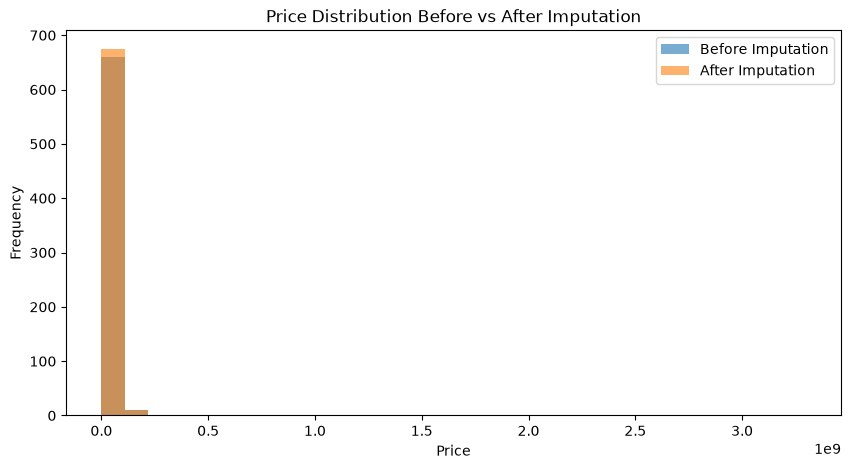

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(
    df_before["price"].dropna(),
    bins=30,
    alpha=0.6,
    label="Before Imputation"
)

plt.hist(
    df_clean["price"],
    bins=30,
    alpha=0.6,
    label="After Imputation"
)

plt.title("Price Distribution Before vs After Imputation")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.legend()
plt.show()


## 10. Validation dữ liệu đầu ra

Kiểm tra các điều kiện cơ bản trước khi xuất Master Dataset:

1. Không còn missing.
2. Không có dòng trùng.
3. Các trường số quan trọng không âm.
4. Rating nằm trong khoảng hợp lệ 0–5.


In [ ]:
# Kiểm tra missing
total_missing = int(df_clean.isna().sum().sum())

# Kiểm tra duplicate
total_duplicates = int(df_clean.duplicated().sum())

# Kiểm tra giá trị âm
negative_price = int((df_clean["price"] < 0).sum())
negative_views = int((df_clean["monthly_views"] < 0).sum())
negative_orders = int((df_clean["monthly_orders"] < 0).sum())
negative_stock = int((df_clean["stock_quantity"] < 0).sum())

# Rating hợp lệ
invalid_customer_rating = int(
    (~df_clean["customer_rating"].between(0, 5)).sum()
)

validation_summary = pd.DataFrame({
    "Check": [
        "Total missing",
        "Duplicate rows",
        "Negative price",
        "Negative monthly_views",
        "Negative monthly_orders",
        "Negative stock_quantity",
        "Invalid customer_rating"
    ],
    "Count": [
        total_missing,
        total_duplicates,
        negative_price,
        negative_views,
        negative_orders,
        negative_stock,
        invalid_customer_rating
    ]
})

display(validation_summary)


,Check,Count
0,Total missing,0
1,Duplicate rows,0
2,Negative price,0
3,Negative monthly_views,0
4,Negative monthly_orders,0
5,Negative stock_quantity,0
6,Invalid customer_rating,0


## 11. Master Dataset hoàn chỉnh

Đây là dataset sau khi hoàn thành Cleaning và Validation.


In [ ]:
master_dataset = df_clean.copy()

print("Kích thước Master Dataset:", master_dataset.shape)
print("Tổng missing:", master_dataset.isna().sum().sum())
print("Tổng duplicate:", master_dataset.duplicated().sum())

display(master_dataset.head())


Kích thước Master Dataset: (689, 21)
Tổng missing: 0
Tổng duplicate: 0


,product_name,price,tv_type,screen_size,resolution,screen_type,operating_system,ram,rom,release_year,...,model_name,rating,num_reviews,specifications,source,monthly_views,monthly_orders,customer_rating,stock_quantity,data_date
0,Smart Tivi QNED LG AI 4K 65 inch 65QNED70BSA,18390000.0,Smart Tivi QNED,65 inch,4K (Ultra HD),Đèn nền: <a href='https://www.dienmayxanh.com/...,webOS 26,Hãng không công bố,Hãng không công bố,2026.0,...,Unknown,4.3,7.0,Unknown,dienmayxanh,7370,453,3.2,145,2026-01-01
1,Google Tivi Sony 4K 65 inch K-65S25VM2,19990000.0,Google Tivi,65 inch,4K (Ultra HD),Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,Hãng không công bố,16 GB,2025.0,...,Unknown,4.3,7.0,Unknown,dienmayxanh,960,373,4.3,66,2026-01-02
2,Google Tivi QLED TCL AI FHD 40 inch 40S5K,7690000.0,Google Tivi QLED,40 inch,Full HD,Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,1 GB,8 GB,2025.0,...,Unknown,4.3,7.0,Unknown,dienmayxanh,5490,492,4.5,41,2026-01-03
3,Google Tivi Sony 32 inch KD-32W830K,7690000.0,Google Tivi,32 inch,HD,Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,Hãng không công bố,16 GB,2022.0,...,Unknown,4.3,7.0,Unknown,dienmayxanh,5291,292,4.7,117,2026-01-04
4,Google Tivi QLED TCL 4K 65 inch 65P7L,18490000.0,Google Tivi QLED,65 inch,4K (Ultra HD),Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,2 GB,16 GB,2026.0,...,Unknown,4.3,7.0,Unknown,dienmayxanh,5834,38,3.2,124,2026-01-05


## 12. Xuất `cleaned_data.csv`

Đây là **đầu ra chính của phần Dương**, được bàn giao cho:

- **Bạn Hải:** Univariate EDA
- **Bạn Tài:** Multivariate EDA

Hai bạn sử dụng `cleaned_data.csv` làm dataset đầu vào để toàn bộ nhóm phân tích trên cùng một phiên bản dữ liệu sạch.


In [ ]:
OUTPUT_FILE = "cleaned_data.csv"

master_dataset.to_csv(
    OUTPUT_FILE,
    index=False,
    encoding="utf-8-sig"
)

print(f"Đã xuất: {OUTPUT_FILE}")


Đã xuất: cleaned_data.csv


## 13. Đọc lại file sau khi xuất – Final Validation

In [ ]:
final_df = pd.read_csv(OUTPUT_FILE)

print("FINAL VALIDATION")
print("-" * 40)
print("Số dòng:", final_df.shape[0])
print("Số cột:", final_df.shape[1])
print("Tổng missing:", int(final_df.isna().sum().sum()))
print("Số dòng trùng:", int(final_df.duplicated().sum()))

display(final_df.head())


FINAL VALIDATION
----------------------------------------
Số dòng: 689
Số cột: 21
Tổng missing: 0
Số dòng trùng: 0


,product_name,price,tv_type,screen_size,resolution,screen_type,operating_system,ram,rom,release_year,...,model_name,rating,num_reviews,specifications,source,monthly_views,monthly_orders,customer_rating,stock_quantity,data_date
0,Smart Tivi QNED LG AI 4K 65 inch 65QNED70BSA,18390000.0,Smart Tivi QNED,65 inch,4K (Ultra HD),Đèn nền: <a href='https://www.dienmayxanh.com/...,webOS 26,Hãng không công bố,Hãng không công bố,2026.0,...,Unknown,4.3,7.0,Unknown,dienmayxanh,7370,453,3.2,145,2026-01-01
1,Google Tivi Sony 4K 65 inch K-65S25VM2,19990000.0,Google Tivi,65 inch,4K (Ultra HD),Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,Hãng không công bố,16 GB,2025.0,...,Unknown,4.3,7.0,Unknown,dienmayxanh,960,373,4.3,66,2026-01-02
2,Google Tivi QLED TCL AI FHD 40 inch 40S5K,7690000.0,Google Tivi QLED,40 inch,Full HD,Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,1 GB,8 GB,2025.0,...,Unknown,4.3,7.0,Unknown,dienmayxanh,5490,492,4.5,41,2026-01-03
3,Google Tivi Sony 32 inch KD-32W830K,7690000.0,Google Tivi,32 inch,HD,Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,Hãng không công bố,16 GB,2022.0,...,Unknown,4.3,7.0,Unknown,dienmayxanh,5291,292,4.7,117,2026-01-04
4,Google Tivi QLED TCL 4K 65 inch 65P7L,18490000.0,Google Tivi QLED,65 inch,4K (Ultra HD),Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,2 GB,16 GB,2026.0,...,Unknown,4.3,7.0,Unknown,dienmayxanh,5834,38,3.2,124,2026-01-05


# KẾT LUẬN

**Pipeline hoàn thành:**

`merged_data.csv`
→ **SQLite (`tv_products.db`)**
→ đọc lại bằng Python
→ **Missing Assessment**
→ **Numeric Median / Categorical Unknown**
→ **Validation**
→ **Master Dataset**
→ `cleaned_data.csv`

`cleaned_data.csv` là dữ liệu đầu vào thống nhất cho bước EDA của bạn Task 3 và Task 4
